
# IoTShield — 09: Birleşik sonuç tablosu ve sunum grafikleri
**SE3513 · WP-F2 · ASEADOS-SDN-IoT**

Bu notebook yeni deney çalıştırmaz. Diğer notebook'ların `run_cv` ile yazdığı sonuç dosyalarını tek tabloda birleştirir (`../reports/results_all.csv`) ve sunum grafiklerini üretir (`../reports/figures/final_*.png`). Sunumdaki her sayı ve grafik buradan gelir.

Bütün grafiklerde aynı sınıf sırası (Benign, Dos, DDoS, Bot, Prob) ve aynı renkler kullanılır.



## 0. Kurulum


In [1]:

import os
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

sys.path.append('..')
from src.config import DATA_PATH
from src.preprocessing import clean
from src.config import F_FULL
from src.cv import make_groups, get_folds, run_cv
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
REPORTS_DIR = '../reports/'
FIG_DIR = '../reports/figures/'
ALL_RESULTS_CSV = REPORTS_DIR + 'results_all.csv'

# One fixed order and one fixed colour per class, used by every figure.
CLASS_ORDER = ['Benign', 'Dos', 'DDoS', 'Bot', 'Prob']
CLASS_COLORS = {'Benign': '#4C72B0', 'Dos': '#DD8452', 'DDoS': '#55A868', 'Bot': '#C44E52', 'Prob': '#8172B3'}



## 1. Sonuç dosyalarını birleştirme → `results_all.csv`
Beş paket sonucu (`source` sütunu dosyanın kaynağını gösterir). `results.csv` ve `results_strong.csv` eski rastgele bölmeye ait olduğu için alınmaz. Henüz olmayan dosyalar listelenir; dosya geldiğinde notebook tekrar çalıştırılır.

Sütun kontrolü: her dosyanın sütunları `run_cv`'nin yazdığı 18 sütunla karşılaştırılır (eksik / fazla / sıra).


In [2]:

RESULT_FILES = {
    'imbalance (WP-B1)': 'results_imbalance.csv',
    'features (WP-B2)': 'results_features.csv',
    'overlap (WP-D2)': 'results_overlap.csv',
    'formulation (WP-D3)': 'results_formulation.csv',
    'final (WP-F1)': 'results_final.csv',
}
# Column order written by src/cv.run_cv
RUN_CV_COLUMNS = ['experiment', 'model', 'sampler', 'feature_set', 'cv', 'macro_f1_mean', 'macro_f1_std',
                  'macro_f1_clean', 'macro_f1_broken', 'recall_Benign', 'recall_Dos', 'recall_DDoS',
                  'recall_Bot', 'recall_Prob', 'bot_ddos_confusion', 'fit_time_s', 'pred_ms_per_flow', 'note']

frames = []
check_rows = []
for source, file_name in RESULT_FILES.items():
    path = REPORTS_DIR + file_name
    if not os.path.exists(path):
        check_rows.append({'source': source, 'dosya': file_name, 'durum': 'YOK (henüz gelmedi)'})
        continue
    frame = pd.read_csv(path)
    missing = [c for c in RUN_CV_COLUMNS if c not in frame.columns]
    extra = [c for c in frame.columns if c not in RUN_CV_COLUMNS]
    check_rows.append({'source': source, 'dosya': file_name, 'durum': 'var', 'satır': len(frame),
                       'eksik_sütun': missing, 'fazla_sütun': extra,
                       'sıra_aynı': list(frame.columns) == RUN_CV_COLUMNS})
    frame.insert(0, 'source', source)
    frames.append(frame)

display(pd.DataFrame(check_rows).set_index('source'))


,dosya,durum,satır,eksik_sütun,fazla_sütun,sıra_aynı
source,,,,,,
imbalance (WP-B1),results_imbalance.csv,var,12,[],[],True
features (WP-B2),results_features.csv,var,9,[],[],True
overlap (WP-D2),results_overlap.csv,var,3,[],[],True
formulation (WP-D3),results_formulation.csv,var,8,[],[],True
final (WP-F1),results_final.csv,var,12,[],[],True


Birleşik tablo `source` + 18 sütun + 2 türetilmiş sütun. Kaynak CSV'lere dokunulmaz; türetilmiş sütunlar sadece burada eklenir:
- **`task`**: satırın hangi görevi ölçtüğü. Farklı görevlerin skorları birbiriyle karşılaştırılmaz: `5-class`, `binary` (Benign / Attack), `Bot-vs-DDoS (broken)` (sadece bozuk Bot + DDoS satırları), `4-class` (Bot + DDoS birleşik).
- **`feature_set_std`**: paketler aynı özellik setini farklı adlarla yazmış (`F_TIMING`, `D_F_TIMING`, `F_timing`); tek tip ad.

In [3]:
FEATURE_SET_NAMES = {
    'F_TIMING': 'F_timing', 'D_F_TIMING': 'F_timing', 'F_timing': 'F_timing',
    'B_F_FULL': 'F_full', 'F_FULL': 'F_full', 'A_FEATS': 'FEATS', 'C_TIMING_COLS_24': 'TIMING_COLS',
    'E_FLOW_DURATION': 'Flow Duration', 'duration_only': 'Flow Duration',
    'F_F_TIMING_DERIVED': 'F_timing + derived', 'G_F_TIMING_BROKEN': 'F_timing + broken',
    'F_full (healthy) / F_timing (broken)': 'F_full / F_timing (routed)',
}


def task_of(row):
    """Returns which task a result row measures (rows of different tasks are not comparable)."""
    if row['source'] == 'overlap (WP-D2)':
        return 'Bot-vs-DDoS (broken)'
    if row['experiment'].startswith('binary_'):
        return 'binary'
    if row['experiment'] == 'D3-11.5-4class':
        return '4-class'
    return '5-class'


all_results = pd.concat(frames, ignore_index=True)
all_results = all_results[['source'] + RUN_CV_COLUMNS]
all_results['task'] = all_results.apply(task_of, axis=1)
all_results['feature_set_std'] = all_results['feature_set'].map(FEATURE_SET_NAMES)
unmapped = all_results.loc[all_results['feature_set_std'].isna(), 'feature_set'].unique()
if len(unmapped) > 0:
    print('UYARI — FEATURE_SET_NAMES içinde olmayan adlar (olduğu gibi bırakıldı):', list(unmapped))
    all_results['feature_set_std'] = all_results['feature_set_std'].fillna(all_results['feature_set'])

all_results.to_csv(ALL_RESULTS_CSV, index=False)
print('results_all.csv:', all_results.shape)
display(pd.crosstab(all_results['source'], all_results['task']))
display(all_results[['source', 'experiment', 'task', 'feature_set_std', 'cv', 'macro_f1_mean', 'macro_f1_std',
                     'macro_f1_clean', 'macro_f1_broken']].round(3))

results_all.csv: (44, 21)


task,4-class,5-class,Bot-vs-DDoS (broken),binary
source,,,,
features (WP-B2),0,7,0,2
final (WP-F1),2,8,0,2
formulation (WP-D3),1,7,0,0
imbalance (WP-B1),0,12,0,0
overlap (WP-D2),0,0,3,0


,source,experiment,task,feature_set_std,cv,macro_f1_mean,macro_f1_std,macro_f1_clean,macro_f1_broken
0,imbalance (WP-B1),E0,5-class,F_timing,grouped,0.418,0.119,0.512,0.324
1,imbalance (WP-B1),E1,5-class,F_timing,grouped,0.397,0.103,0.502,0.277
2,imbalance (WP-B1),E2,5-class,F_timing,grouped,0.427,0.118,0.527,0.326
3,imbalance (WP-B1),E3,5-class,F_timing,grouped,0.425,0.124,0.524,0.322
4,imbalance (WP-B1),E4,5-class,F_timing,grouped,0.419,0.119,0.526,0.316
5,imbalance (WP-B1),E5,5-class,F_timing,grouped,0.407,0.115,0.511,0.305
6,imbalance (WP-B1),E6,5-class,F_timing,grouped,0.414,0.120,0.519,0.312
7,imbalance (WP-B1),E7,5-class,F_timing,grouped,0.383,0.079,0.499,0.310
8,imbalance (WP-B1),E8,5-class,F_timing,grouped,0.452,0.080,0.764,0.267
9,imbalance (WP-B1),E9,5-class,F_timing,grouped,0.430,0.124,0.516,0.340



## 2. Veri (grafik 1, 2 ve 5 için)
`clean()` verisi ve oturumlar (`make_groups`, değerlendirmedeki gruplarla aynı).


In [4]:

data = clean(pd.read_csv(DATA_PATH, low_memory=False))
data['session'] = make_groups(data)
print(data.shape)


clean: dropped 70 rows with inf/NaN
clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)
clean: final shape (427044, 63)


(427044, 64)



## Grafik 1 — Sınıf dağılımı (log) ve sağlam / bozuk kırılımı
Sol: `clean()` sonrası sınıf başına satır sayısı (log ölçek). Sağ: her sınıfın yüzde kaçı sağlam, yüzde kaçı bozuk (`Protocol == 0`). Bozuk kısım taralı.


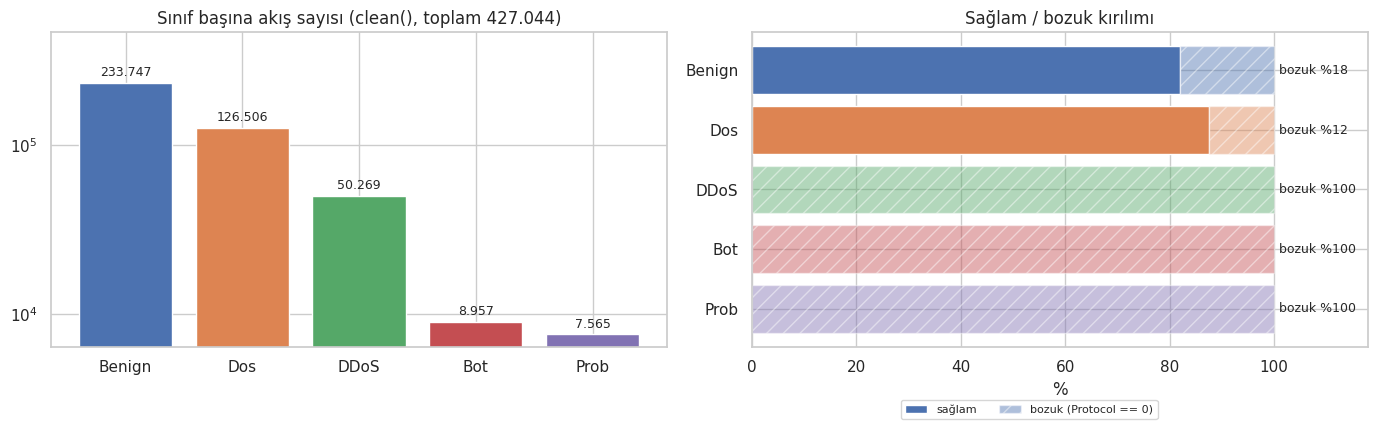

,satır,bozuk_%
Label,,
Benign,233747,17.9
Dos,126506,12.4
DDoS,50269,100.0
Bot,8957,100.0
Prob,7565,100.0


In [5]:

counts = data['Label'].value_counts().reindex(CLASS_ORDER)
broken_share = data.groupby('Label')['broken'].mean().reindex(CLASS_ORDER) * 100
colors = [CLASS_COLORS[label] for label in CLASS_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(CLASS_ORDER, counts.values, color=colors)
axes[0].set_yscale('log')
axes[0].set_ylim(top=counts.max() * 2)
total_text = f'{len(data):,}'.replace(',', '.')
axes[0].set_title(f'Sınıf başına akış sayısı (clean(), toplam {total_text})')
for x, value in enumerate(counts.values):
    axes[0].text(x, value * 1.1, f'{value:,}'.replace(',', '.'), ha='center', fontsize=9)

healthy_share = 100 - broken_share
axes[1].barh(CLASS_ORDER, healthy_share.values, color=colors, label='sağlam')
axes[1].barh(CLASS_ORDER, broken_share.values, left=healthy_share.values, color=colors, alpha=0.45,
             hatch='//', edgecolor='white', label='bozuk (Protocol == 0)')
for y, value in enumerate(broken_share.values):
    axes[1].text(101, y, f'bozuk %{value:.0f}', va='center', fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 118); axes[1].set_xlabel('%')
axes[1].set_title('Sağlam / bozuk kırılımı')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.45, -0.15), ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_1_class_distribution.png', dpi=150, bbox_inches='tight'); plt.show()
display(pd.DataFrame({'satır': counts, 'bozuk_%': broken_share.round(1)}))



## Grafik 2 — Sınıf başına kayıt oturumları
Sol: sınıf başına oturum sayısı (oturum = ardışık dakikalar; değerlendirmede grup). Sağ: Bot ve DDoS oturumlarının zaman ekseni (her sınıfın ilk akışından itibaren dakika); çubuk üstünde oturumdaki akış sayısı.


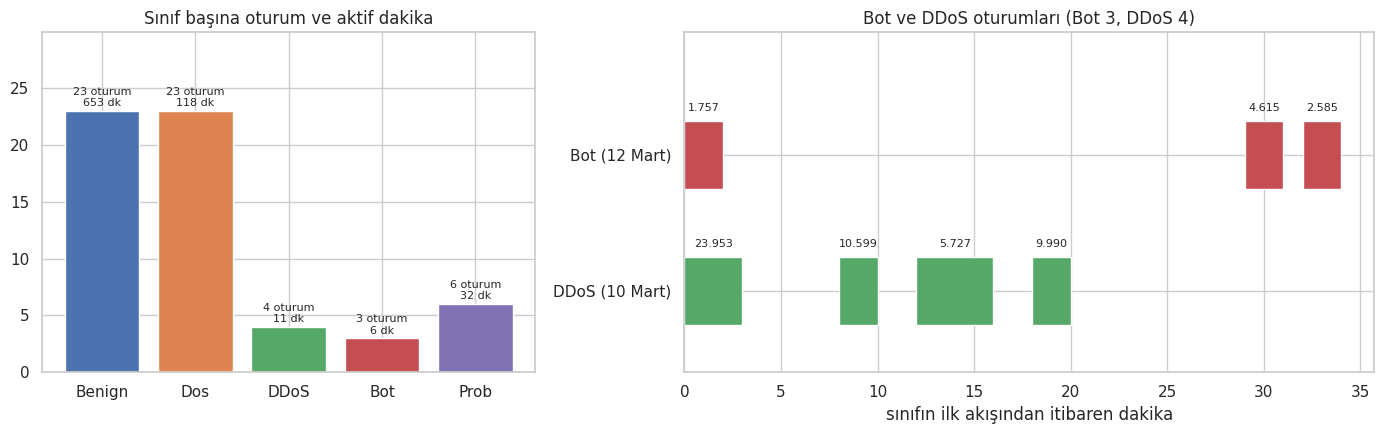

,oturum,aktif_dk
Label,,
Benign,23,653
Dos,23,118
DDoS,4,11
Bot,3,6
Prob,6,32


In [6]:

session_counts = data.groupby('Label')['session'].nunique().reindex(CLASS_ORDER)
active_minutes = data.groupby('Label')['minute'].nunique().reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].bar(CLASS_ORDER, session_counts.values, color=colors)
for x, label in enumerate(CLASS_ORDER):
    axes[0].text(x, session_counts[label] + 0.4, f'{session_counts[label]} oturum\n{active_minutes[label]} dk',
                 ha='center', fontsize=8)
axes[0].set_ylim(0, session_counts.max() * 1.3)
axes[0].set_title('Sınıf başına oturum ve aktif dakika')

for y, label in enumerate(['DDoS', 'Bot']):
    part = data[data['Label'] == label]
    start_minute = part['minute'].min()
    sessions = part.groupby('session')['minute'].agg(['min', 'max', 'count'])
    for _, s in sessions.iterrows():
        left = s['min'] - start_minute
        width = s['max'] - s['min'] + 1
        axes[1].barh(y, width, left=left, color=CLASS_COLORS[label], height=0.5)
        axes[1].text(left + width / 2, y + 0.32, f"{s['count']:,}".replace(',', '.'), ha='center', fontsize=8)
axes[1].set_yticks([0, 1], ['DDoS (10 Mart)', 'Bot (12 Mart)'])
axes[1].set_ylim(-0.6, 1.9)
axes[1].set_xlabel('sınıfın ilk akışından itibaren dakika')
axes[1].set_title('Bot ve DDoS oturumları (Bot 3, DDoS 4)')
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_2_sessions.png', dpi=150, bbox_inches='tight'); plt.show()
display(pd.DataFrame({'oturum': session_counts, 'aktif_dk': active_minutes}))



## Grafik 3 — Rastgele vs oturum gruplu CV (aynı satırlar)
`results_all.csv`'de aynı deneyin hem rastgele hem gruplu katlarla çalıştırıldığı satırlar (WP-B1: E0 ve E9; LightGBM, F_timing). Her deney için tüm veri, sağlam ve bozuk alt küme macro F1. Hata çubuğu sadece "tüm veri" için (katlar arası std); sağlam / bozuk skor birleşik OOF tahminlerinden tek bir sayı olduğu için std'si yok.


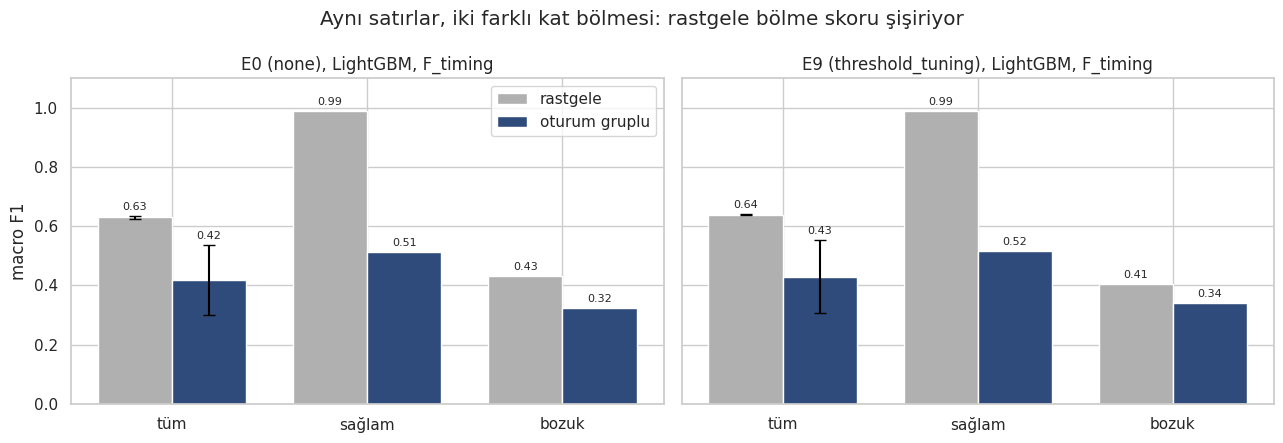

cv,grouped,random,fark
experiment,,,
E0,0.418,0.630,0.212
E9,0.430,0.639,0.209


In [7]:

CV_COLORS = {'random': '#B0B0B0', 'grouped': '#2F4B7C'}
SCORE_COLUMNS = {'tüm': 'macro_f1_mean', 'sağlam': 'macro_f1_clean', 'bozuk': 'macro_f1_broken'}

imbalance = all_results[all_results['source'] == 'imbalance (WP-B1)']
paired_experiments = ['E0', 'E9']
bar_width = 0.38
x = np.arange(len(SCORE_COLUMNS))

fig, axes = plt.subplots(1, len(paired_experiments), figsize=(13, 4.5), sharey=True)
for ax, experiment in zip(axes, paired_experiments):
    for offset, cv in [(-bar_width / 2, 'random'), (bar_width / 2, 'grouped')]:
        row = imbalance[(imbalance['experiment'] == experiment) & (imbalance['cv'] == cv)].iloc[0]
        values = [row[col] for col in SCORE_COLUMNS.values()]
        ax.bar(x + offset, values, bar_width, color=CV_COLORS[cv],
               label='rastgele' if cv == 'random' else 'oturum gruplu')
        # error bar only for the "all data" score (fold std); healthy/broken are single OOF numbers
        ax.errorbar(x[0] + offset, values[0], yerr=row['macro_f1_std'], color='black', capsize=4)
        label_heights = [values[0] + row['macro_f1_std'], values[1], values[2]]
        for xi, value, height in zip(x + offset, values, label_heights):
            ax.text(xi, height + 0.02, f'{value:.2f}', ha='center', fontsize=8)
    ax.set_xticks(x, list(SCORE_COLUMNS.keys()))
    ax.set_title(f'{experiment} ({row["sampler"]}), LightGBM, F_timing')
    ax.set_ylim(0, 1.1)
axes[0].set_ylabel('macro F1')
axes[0].legend(loc='upper right')
fig.suptitle('Aynı satırlar, iki farklı kat bölmesi: rastgele bölme skoru şişiriyor')
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_3_random_vs_grouped.png', dpi=150, bbox_inches='tight'); plt.show()

inflation = imbalance.pivot(index='experiment', columns='cv', values='macro_f1_mean').dropna()
inflation['fark'] = inflation['random'] - inflation['grouped']
display(inflation.round(3))



## Grafik 4 — Imbalance yöntemleri (WP-B1): tüm / bozuk macro F1
Gruplu CV, LightGBM (E8: BalancedRandomForest), F_timing. Koyu çubuk: tüm veri macro F1, hata çubuğu katlar arası std. Açık çubuk: bozuk alt küme macro F1 (tek sayı, std yok). Kesikli çizgiler: E0 (yöntem yok) referansı.

Not (WP-B1): E7 (ENN) çıktısında LightGBM çok iş parçacıklı çalıştığı için skor Run All'dan Run All'a yaklaşık ±0,01 oynuyor; katlar arası std'nin altında.


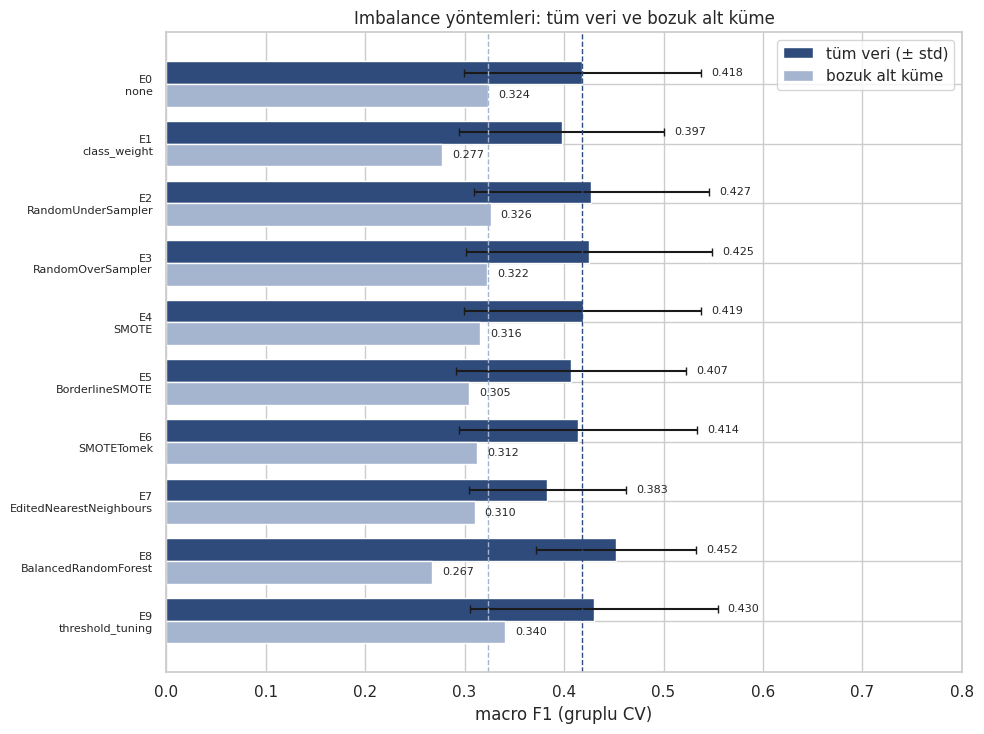

,experiment,sampler,macro_f1_mean,macro_f1_std,macro_f1_broken,recall_Bot,recall_DDoS,note
0,E0,none,0.418,0.119,0.324,0.031,0.713,NaN
1,E1,class_weight,0.397,0.103,0.277,0.667,0.413,class_weight=balanced
2,E2,RandomUnderSampler,0.427,0.118,0.326,0.030,0.824,"Benign, Dos -> min(50k, available); fold 2 Dos..."
3,E3,RandomOverSampler,0.425,0.124,0.322,0.542,0.365,"Bot, Prob -> 30k"
4,E4,SMOTE,0.419,0.119,0.316,0.575,0.353,"log1p + scaler; Bot, Prob -> 30k"
5,E5,BorderlineSMOTE,0.407,0.115,0.305,0.517,0.362,"log1p + scaler; Bot, Prob -> 30k"
6,E6,SMOTETomek,0.414,0.120,0.312,0.591,0.328,"log1p + scaler; Bot, Prob -> 30k, then Tomek l..."
7,E7,EditedNearestNeighbours,0.383,0.079,0.310,0.207,0.537,log1p + scaler; ENN default
8,E8,BalancedRandomForest,0.452,0.080,0.267,0.398,0.534,model RF (n_estimators=200)
9,E9,threshold_tuning,0.430,0.124,0.340,0.289,0.514,weights chosen on inner validation (broken F1)...


In [8]:

grouped_imbalance = imbalance[imbalance['cv'] == 'grouped'].reset_index(drop=True)
labels = [f"{e}\n{s}" for e, s in zip(grouped_imbalance['experiment'], grouped_imbalance['sampler'])]
y = np.arange(len(grouped_imbalance))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(y - bar_height / 2, grouped_imbalance['macro_f1_mean'], bar_height,
        xerr=grouped_imbalance['macro_f1_std'], capsize=3, color='#2F4B7C', label='tüm veri (± std)')
ax.barh(y + bar_height / 2, grouped_imbalance['macro_f1_broken'], bar_height, color='#A5B4CF', label='bozuk alt küme')
e0 = grouped_imbalance[grouped_imbalance['experiment'] == 'E0'].iloc[0]
ax.axvline(e0['macro_f1_mean'], color='#2F4B7C', linestyle='--', linewidth=1)
ax.axvline(e0['macro_f1_broken'], color='#A5B4CF', linestyle='--', linewidth=1)
for yi, (total, std, broken_score) in enumerate(zip(grouped_imbalance['macro_f1_mean'], grouped_imbalance['macro_f1_std'],
                                                    grouped_imbalance['macro_f1_broken'])):
    ax.text(total + std + 0.01, yi - bar_height / 2, f'{total:.3f}', va='center', fontsize=8)
    ax.text(broken_score + 0.01, yi + bar_height / 2, f'{broken_score:.3f}', va='center', fontsize=8)
ax.set_yticks(y, labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 0.8)
ax.set_xlabel('macro F1 (gruplu CV)')
ax.set_title('Imbalance yöntemleri: tüm veri ve bozuk alt küme')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_4_imbalance.png', dpi=150, bbox_inches='tight'); plt.show()
display(grouped_imbalance[['experiment', 'sampler', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_broken',
                           'recall_Bot', 'recall_DDoS', 'note']].round(3))



## Grafik 5 — Bozuk satırlarda süre dağılımı + özellik seti ablation'ı
Sol: bozuk satırlarda `log1p(Flow Duration)`, sınıf başına yoğunluk (her eğri kendi sınıfı içinde normalize; Bot ve DDoS kalın ve dolgulu). 05_overlap 9.3 ile aynı ölçüm, ortak paletle. Sağ: WP-B2 ablation'ı (gruplu CV, LightGBM, 5 sınıf): tüm veri (± std), sağlam ve bozuk alt küme macro F1. Bozuk alt kümede A–D, F, G setleri arasında fark küçük (0,324–0,343). Sadece `Flow Duration` (E) bozuk alt kümede 0,189 ile belirgin şekilde düşük: 5 sınıflı bozuk alt kümede diğer zamanlama sütunları bilgi ekliyor. (Sadece bozuk Bot vs DDoS'ta ise süre ≈ F_timing; 05_overlap 9.1.)


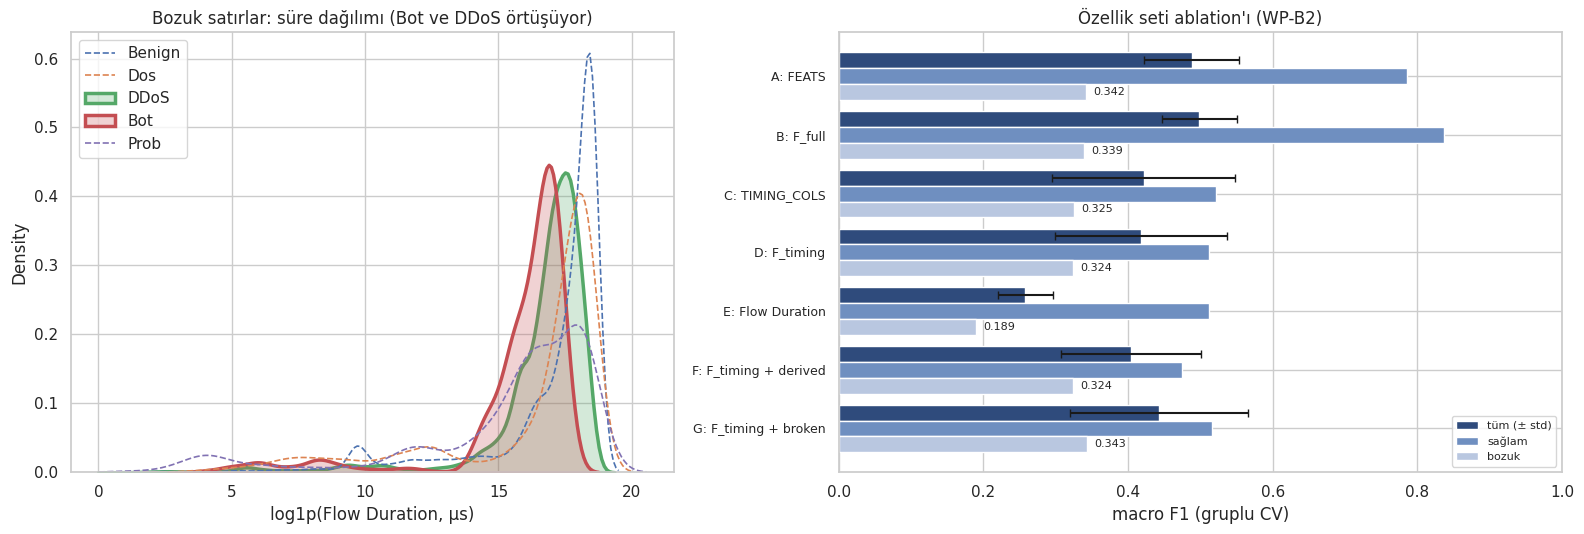

Label
Benign    66.9
Dos       50.6
DDoS      27.5
Bot       15.4
Prob      15.5
Name: medyan süre (sn), dtype: float64

,experiment,feature_set_std,macro_f1_mean,macro_f1_std,macro_f1_clean,macro_f1_broken
0,ablation_A,FEATS,0.488,0.065,0.786,0.342
1,ablation_B,F_full,0.499,0.052,0.837,0.339
2,ablation_C,TIMING_COLS,0.422,0.126,0.521,0.325
3,ablation_D,F_timing,0.418,0.119,0.512,0.324
4,ablation_E,Flow Duration,0.258,0.038,0.512,0.189
5,ablation_F,F_timing + derived,0.404,0.097,0.474,0.324
6,ablation_G,F_timing + broken,0.443,0.123,0.516,0.343


In [9]:

broken_rows = data[data['broken']].copy()
broken_rows['log_duration'] = np.log1p(broken_rows['Flow Duration'])

ablation = all_results[(all_results['source'] == 'features (WP-B2)') & (all_results['task'] == '5-class')]
ablation = ablation.reset_index(drop=True)
ablation_labels = [f"{e.replace('ablation_', '')}: {s}" for e, s in zip(ablation['experiment'], ablation['feature_set_std'])]
SUBSET_COLORS = {'tüm': '#2F4B7C', 'sağlam': '#6F8FC0', 'bozuk': '#B9C7E0'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
for label in CLASS_ORDER:
    part = broken_rows[broken_rows['Label'] == label]
    emphasis = label in ['Bot', 'DDoS']
    if emphasis:
        sns.kdeplot(part['log_duration'], ax=axes[0], color=CLASS_COLORS[label], clip=(0, None),
                    fill=True, alpha=0.25, linewidth=2.5, label=label)
    else:
        sns.kdeplot(part['log_duration'], ax=axes[0], color=CLASS_COLORS[label], clip=(0, None),
                    linewidth=1.2, linestyle='--', label=label)
axes[0].set_xlabel('log1p(Flow Duration, µs)')
axes[0].set_title('Bozuk satırlar: süre dağılımı (Bot ve DDoS örtüşüyor)')
axes[0].legend()

y = np.arange(len(ablation))
bar_height = 0.27
axes[1].barh(y - bar_height, ablation['macro_f1_mean'], bar_height, xerr=ablation['macro_f1_std'], capsize=3,
             color=SUBSET_COLORS['tüm'], label='tüm (± std)')
axes[1].barh(y, ablation['macro_f1_clean'], bar_height, color=SUBSET_COLORS['sağlam'], label='sağlam')
axes[1].barh(y + bar_height, ablation['macro_f1_broken'], bar_height, color=SUBSET_COLORS['bozuk'], label='bozuk')
for yi, value in enumerate(ablation['macro_f1_broken']):
    axes[1].text(value + 0.01, yi + bar_height, f'{value:.3f}', va='center', fontsize=8)
axes[1].set_yticks(y, ablation_labels, fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('macro F1 (gruplu CV)')
axes[1].set_title('Özellik seti ablation\'ı (WP-B2)')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_5_duration_and_ablation.png', dpi=150, bbox_inches='tight'); plt.show()

duration_seconds = broken_rows['Flow Duration'] / 1_000_000
display(duration_seconds.groupby(broken_rows['Label']).median().reindex(CLASS_ORDER).round(1).rename('medyan süre (sn)'))
display(ablation[['experiment', 'feature_set_std', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean', 'macro_f1_broken']].round(3))



## Grafik 6a — Final tablo (WP-F1, `results_final.csv`)
WP-F1'in seçtiği yapılandırmalar; her biri hem gruplu hem rastgele CV ile. Raporlanan skor **gruplu** CV; rastgele CV sadece şişirmeyi göstermek için (italik değil, ayrı sütun). Görevler farklı satırlar birbiriyle karşılaştırılmaz (`task`).


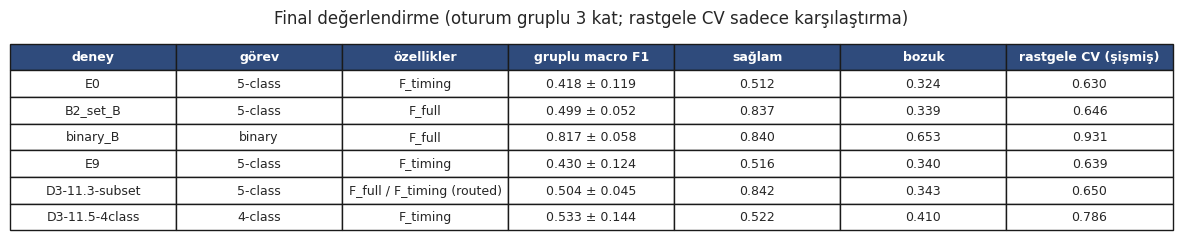

,deney,görev,özellikler,gruplu macro F1,sağlam,bozuk,rastgele CV (şişmiş)
0,E0,5-class,F_timing,0.418 ± 0.119,0.512,0.324,0.630
1,B2_set_B,5-class,F_full,0.499 ± 0.052,0.837,0.339,0.646
2,binary_B,binary,F_full,0.817 ± 0.058,0.840,0.653,0.931
3,E9,5-class,F_timing,0.430 ± 0.124,0.516,0.340,0.639
4,D3-11.3-subset,5-class,F_full / F_timing (routed),0.504 ± 0.045,0.842,0.343,0.650
5,D3-11.5-4class,4-class,F_timing,0.533 ± 0.144,0.522,0.410,0.786


In [10]:

final = all_results[all_results['source'] == 'final (WP-F1)']
grouped_final = final[final['cv'] == 'grouped'].set_index('experiment')
random_final = final[final['cv'] == 'random'].set_index('experiment')

table_rows = []
for experiment, row in grouped_final.iterrows():
    table_rows.append([experiment, row['task'], row['feature_set_std'],
                       f"{row['macro_f1_mean']:.3f} ± {row['macro_f1_std']:.3f}",
                       f"{row['macro_f1_clean']:.3f}", f"{row['macro_f1_broken']:.3f}",
                       f"{random_final.loc[experiment, 'macro_f1_mean']:.3f}"])
columns = ['deney', 'görev', 'özellikler', 'gruplu macro F1', 'sağlam', 'bozuk', 'rastgele CV (şişmiş)']

fig, ax = plt.subplots(figsize=(15, 0.32 * len(table_rows) + 0.6))
ax.axis('off')
table = ax.table(cellText=table_rows, colLabels=columns, loc='center', cellLoc='center')
table.auto_set_font_size(False); table.set_fontsize(9); table.scale(1, 1.6)
for col in range(len(columns)):
    table[0, col].set_facecolor('#2F4B7C'); table[0, col].set_text_props(color='white', weight='bold')
ax.set_title('Final değerlendirme (oturum gruplu 3 kat; rastgele CV sadece karşılaştırma)', pad=12)
plt.savefig(FIG_DIR + 'final_6a_final_table.png', dpi=150, bbox_inches='tight'); plt.show()
display(pd.DataFrame(table_rows, columns=columns))



## Grafik 6b — Final 5 sınıflı model (Set B: LightGBM, F_full): confusion matrix'ler
WP-F1'in seçtiği 5 sınıflı model. `results_final.csv` confusion matrix'i içermediği için model aynı katlarla `run_cv` ile bir kez daha çalıştırılır (sonuç satırı git dışındaki geçici bir dosyaya yazılır; skor `results_final.csv`'deki B2_set_B satırıyla aynı olmalı). Matrisler satır bazında normalize (satır = gerçek sınıf); sol: sağlam satırlar (sadece Benign / Dos), sağ: bozuk satırlar (5 sınıf).


Kat 0


  eğitim: 304139 satır (çelişki atılan: 1000 ) | test: 121905 | fit: 10.1 sn
Kat 1


  eğitim: 314008 satır (çelişki atılan: 860 ) | test: 112176 | fit: 9.2 sn
Kat 2


  eğitim: 233464 satır (çelişki atılan: 617 ) | test: 192963 | fit: 7.9 sn


Kat F1'leri: [0.4554 0.5563 0.4847] → 0.4988 ± 0.0519
CSV'ye eklendi: ../data/processed/f2_final_model_tmp.csv


run_cv: 0.4988 | results_final.csv: 0.4988


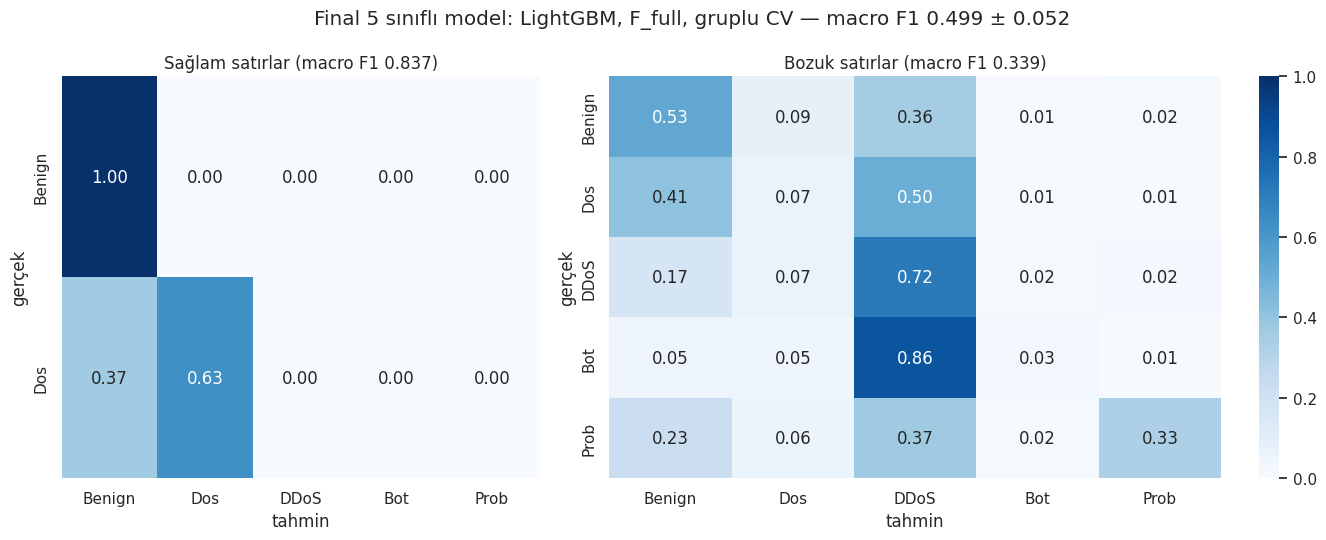

oof_pred,Benign,Dos,DDoS,Bot,Prob
Label,,,,,
Benign,0.998,0.002,0.0,0.0,0.0
Dos,0.370,0.630,0.0,0.0,0.0


oof_pred,Benign,Dos,DDoS,Bot,Prob
Label,,,,,
Benign,0.528,0.090,0.358,0.007,0.017
Dos,0.410,0.066,0.501,0.011,0.012
DDoS,0.175,0.068,0.718,0.017,0.022
Bot,0.051,0.050,0.858,0.033,0.007
Prob,0.226,0.056,0.374,0.016,0.329


In [11]:

TEMP_CSV = '../data/processed/f2_final_model_tmp.csv'   # data/ is not in git
if os.path.exists(TEMP_CSV):
    os.remove(TEMP_CSV)

final_pipe = Pipeline([('model', LGBMClassifier(random_state=42, verbose=-1))])
row, cm_all, oof = run_cv(final_pipe, data, F_FULL, TEMP_CSV, experiment='B2_set_B (F2 rerun)', sampler='none',
                          feature_set='F_FULL', folds=get_folds(data), note='F2 figure 6 only')
expected = grouped_final.loc['B2_set_B', 'macro_f1_mean']
print(f"run_cv: {row['macro_f1_mean']:.4f} | results_final.csv: {expected:.4f}")
assert round(row['macro_f1_mean'], 4) == round(expected, 4)


def normalized_confusion(rows_mask, true_classes):
    """Row-normalised confusion matrix for the selected rows (rows = true class, columns = predicted)."""
    counts = pd.crosstab(data.loc[rows_mask, 'Label'], oof[rows_mask]).reindex(index=true_classes, columns=CLASS_ORDER, fill_value=0)
    return counts.div(counts.sum(axis=1), axis=0)


is_broken = data['broken'].to_numpy()
cm_healthy = normalized_confusion(~is_broken, ['Benign', 'Dos'])
cm_broken = normalized_confusion(is_broken, CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})
sns.heatmap(cm_healthy, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=axes[0])
axes[0].set_title(f'Sağlam satırlar (macro F1 {row["macro_f1_clean"]:.3f})')
sns.heatmap(cm_broken, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title(f'Bozuk satırlar (macro F1 {row["macro_f1_broken"]:.3f})')
for ax in axes:
    ax.set_xlabel('tahmin'); ax.set_ylabel('gerçek')
fig.suptitle(f'Final 5 sınıflı model: LightGBM, F_full, gruplu CV — macro F1 {row["macro_f1_mean"]:.3f} ± {row["macro_f1_std"]:.3f}')
plt.tight_layout()
plt.savefig(FIG_DIR + 'final_6b_confusion_matrices.png', dpi=150, bbox_inches='tight'); plt.show()
display(cm_healthy.round(3)); display(cm_broken.round(3))
